In [ ]:
# Install all required libraries
import subprocess
subprocess.run(['pip', 'install', 'tensorflow', 'scikit-learn',
                'pillow', 'matplotlib', 'seaborn', '-q'])

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os
import random
from PIL import Image
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import EfficientNetB3
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import img_to_array, load_img
import warnings
warnings.filterwarnings('ignore')

print('✅ All libraries imported successfully!')
print(f'TensorFlow version: {tf.__version__}')


✅ All libraries imported successfully!
TensorFlow version: 2.19.0


In [ ]:
# Install opendatasets for easy Kaggle downloads
!pip install opendatasets -q
import opendatasets as od

# This will ask for your Kaggle username and API key
# Username: your Kaggle profile name (e.g. ItadoriYuji0311)
# Key: the API token from Kaggle Settings → API → Create New Token
od.download('https://www.kaggle.com/datasets/aarishasifkhan/plantvillage-potato-disease-dataset')

import os
print('Done! Checking folders...')
for root, dirs, files in os.walk('plantvillage-potato-disease-dataset'):
    level = root.count(os.sep)
    if level <= 2:
        print(' ' * level * 2 + os.path.basename(root) + '/')


Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: AiswaryaAjith83
Your Kaggle Key: ··········
Dataset URL: https://www.kaggle.com/datasets/aarishasifkhan/plantvillage-potato-disease-dataset


100%|██████████| 37.8M/37.8M [00:00<00:00, 2.05GB/s]

Done! Checking folders...
plantvillage-potato-disease-dataset/
  PlantVillage/
    Potato___Late_blight/
    Potato___healthy/
    Potato___Early_blight/


In [ ]:
import os

dataset_dir = 'plantvillage-potato-disease-dataset/PlantVillage'
class_dirs  = ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']
class_labels = ['Early Blight', 'Late Blight', 'Healthy']

print(f'✅ Dataset path set: {dataset_dir}')
print('\nVerifying folders...')
for c in class_dirs:
    count = len(os.listdir(os.path.join(dataset_dir, c)))
    print(f'  📁 {c}: {count} images')


✅ Dataset path set: plantvillage-potato-disease-dataset/PlantVillage

Verifying folders...
  📁 Potato___Early_blight: 1000 images
  📁 Potato___Late_blight: 1000 images
  📁 Potato___healthy: 152 images


Total images: 2152
  Early Blight: 1000 images (46.5%)
  Late Blight: 1000 images (46.5%)
  Healthy: 152 images (7.1%)


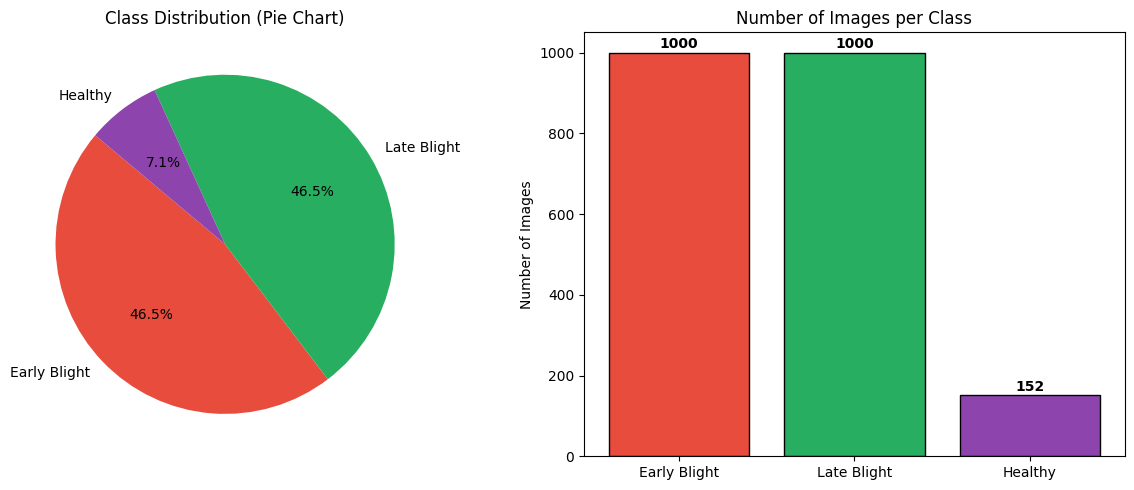

✅ Chart saved!


In [ ]:
import matplotlib.pyplot as plt

class_counts = []
for class_dir in class_dirs:
    class_path = os.path.join(dataset_dir, class_dir)
    class_counts.append(len(os.listdir(class_path)))

total_images = sum(class_counts)
print(f'Total images: {total_images}')
for label, count in zip(class_labels, class_counts):
    print(f'  {label}: {count} images ({count/total_images*100:.1f}%)')

colors = ['#e74c3c', '#27ae60', '#8e44ad']
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.pie(class_counts, labels=class_labels, autopct='%1.1f%%',
        startangle=140, colors=colors)
ax1.set_title('Class Distribution (Pie Chart)')

ax2.bar(class_labels, class_counts, color=colors, edgecolor='black')
ax2.set_title('Number of Images per Class')
ax2.set_ylabel('Number of Images')
for i, v in enumerate(class_counts):
    ax2.text(i, v + 10, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Chart saved!')


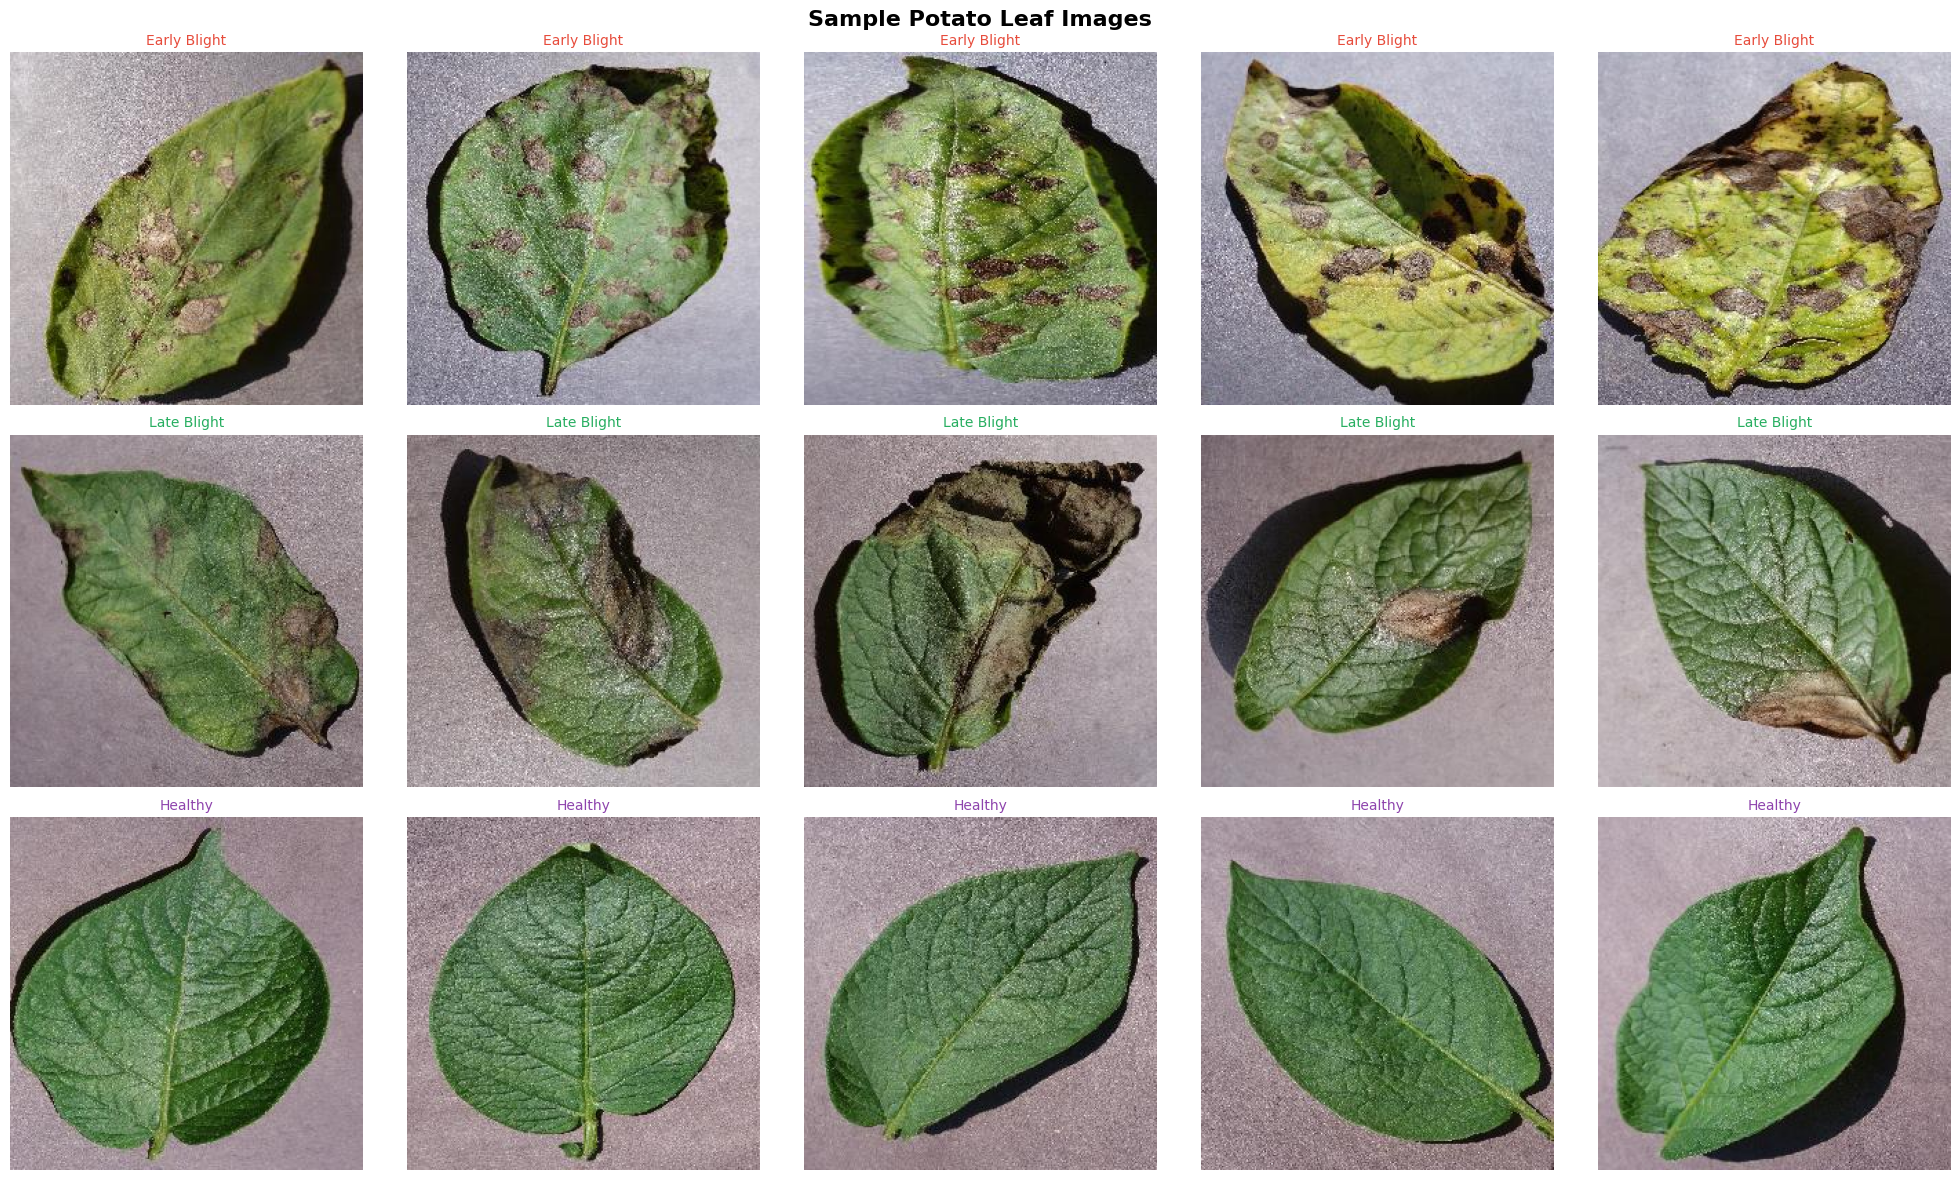

✅ Sample images displayed!


In [ ]:
from PIL import Image

fig, axes = plt.subplots(3, 5, figsize=(20, 12))
fig.suptitle('Sample Potato Leaf Images', fontsize=16, fontweight='bold')
colors = ['#e74c3c', '#27ae60', '#8e44ad']

for row, (class_dir, label) in enumerate(zip(class_dirs, class_labels)):
    class_path = os.path.join(dataset_dir, class_dir)
    image_files = os.listdir(class_path)[:5]
    for col, img_file in enumerate(image_files):
        img = Image.open(os.path.join(class_path, img_file))
        axes[row, col].imshow(img)
        axes[row, col].set_title(label, fontsize=10, color=colors[row])
        axes[row, col].axis('off')

plt.tight_layout()
plt.savefig('sample_images.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Sample images displayed!')


In [ ]:
base_dir = dataset_dir

# Augmentation for training — adds realistic distortions
train_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.efficientnet.preprocess_input,
    validation_split=0.2,
    horizontal_flip=True,
    zoom_range=0.3,
    shear_range=0.3,
    rotation_range=40,
    width_shift_range=0.3,
    height_shift_range=0.3,
    fill_mode='nearest'
)

# No augmentation for validation
val_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.efficientnet.preprocess_input,
    validation_split=0.2
)

train_generator = train_datagen.flow_from_directory(
    base_dir,
    target_size=(300, 300),
    batch_size=16,
    class_mode='categorical',
    subset='training',
    seed=42
)

validation_generator = val_datagen.flow_from_directory(
    base_dir,
    target_size=(300, 300),
    batch_size=16,
    class_mode='categorical',
    subset='validation',
    seed=42
)

print(f'\n✅ Training images:   {train_generator.samples}')
print(f'✅ Validation images: {validation_generator.samples}')
print(f'✅ Classes: {train_generator.class_indices}')


Found 1722 images belonging to 3 classes.
Found 430 images belonging to 3 classes.

✅ Training images:   1722
✅ Validation images: 430
✅ Classes: {'Potato___Early_blight': 0, 'Potato___Late_blight': 1, 'Potato___healthy': 2}


In [ ]:
import numpy as np
from tensorflow.keras.applications import EfficientNetB3
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from sklearn.utils.class_weight import compute_class_weight

# Check GPU
print('GPU available:', tf.config.list_physical_devices('GPU'))

# Handle class imbalance
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_generator.classes),
    y=train_generator.classes
)
class_weights_dict = dict(enumerate(class_weights))
print('Class weights:', class_weights_dict)

# Load EfficientNetB3 pre-trained on ImageNet
base_model = EfficientNetB3(weights='imagenet', include_top=False,
                            input_shape=(300, 300, 3))

# Add custom classification layers
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.5)(x)
x = Dense(1024, activation='relu')(x)
x = Dropout(0.5)(x)
predictions = Dense(3, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=predictions)

# Freeze base model layers
for layer in base_model.layers:
    layer.trainable = False

model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print(f'\n✅ Model built! Parameters: {model.count_params():,}')
print('\n⏳ Starting training...\n')

early_stopping = EarlyStopping(monitor='val_loss', patience=5,
                               restore_best_weights=True)
checkpoint     = ModelCheckpoint('best_model.keras', monitor='val_loss',
                                 save_best_only=True)
reduce_lr      = ReduceLROnPlateau(monitor='val_loss', factor=0.2,
                                   patience=3, min_lr=1e-6)

# Reset generators before training
train_generator.reset()
validation_generator.reset()

history = model.fit(
    train_generator,
    steps_per_epoch=len(train_generator),
    validation_data=validation_generator,
    validation_steps=len(validation_generator),
    epochs=50,
    class_weight=class_weights_dict,
    callbacks=[early_stopping, checkpoint, reduce_lr]
)

print('\n✅ Training complete!')
print(f'Best validation accuracy: {max(history.history["val_accuracy"])*100:.2f}%')

GPU available: []
Class weights: {0: np.float64(0.7175), 1: np.float64(0.7175), 2: np.float64(4.704918032786885)}
43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step

✅ Model built! Parameters: 12,360,498

⏳ Starting training...

Epoch 1/50
108/108 ━━━━━━━━━━━━━━━━━━━━ 373s 3s/step - accuracy: 0.6630 - loss: 0.8545 - val_accuracy: 0.9209 - val_loss: 0.3172 - learning_rate: 1.0000e-04
Epoch 2/50
108/108 ━━━━━━━━━━━━━━━━━━━━ 358s 3s/step - accuracy: 0.9025 - loss: 0.2985 - val_accuracy: 0.9209 - val_loss: 0.2315 - learning_rate: 1.0000e-04
Epoch 3/50
108/108 ━━━━━━━━━━━━━━━━━━━━ 393s 3s/step - accuracy: 0.9065 - loss: 0.2647 - val_accuracy: 0.9116 - val_loss: 0.2309 - learning_rate: 1.0000e-04
Epoch 4/50
108/108 ━━━━━━━━━━━━━━━━━━━━ 361s 3s/step - accuracy: 0.9177 - loss: 0.2095 - val_accuracy: 0.9093 - val_loss: 0.2169 - learning_rate: 1.0000e-04
Epoch 5/50
108/108 ━━━━━━━━━━━━━━━━━━━━ 366s 3s/step - accuracy: 0.9202 - loss: 0.2092 - val_accuracy: 0.9326 - val_loss: 0.1816 - learning_rat

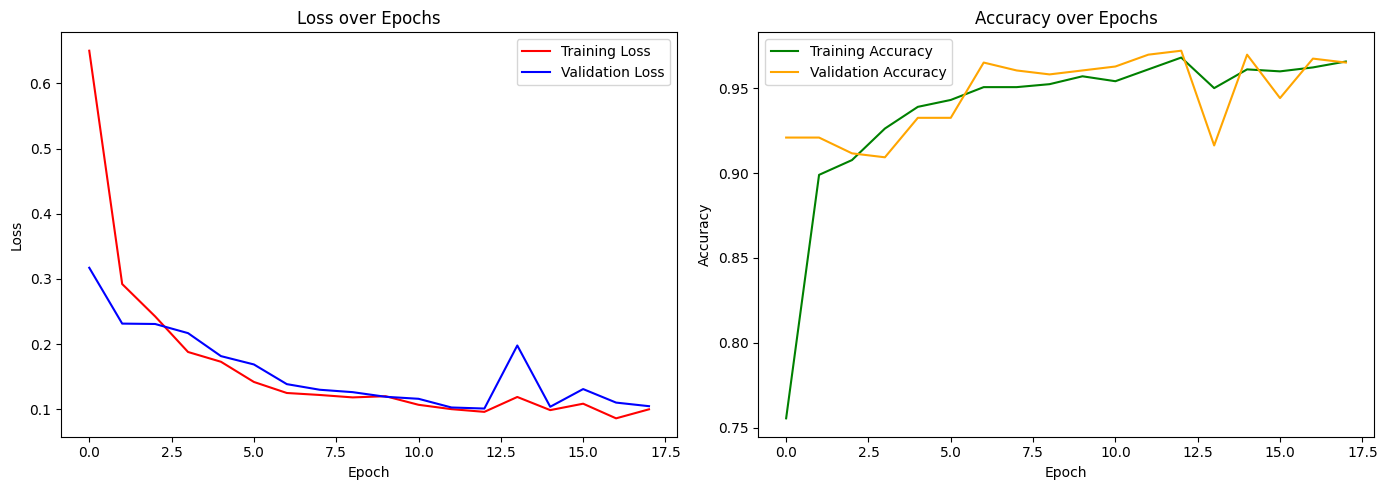

✅ Training curves saved!


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'],     label='Training Loss',   color='red')
plt.plot(history.history['val_loss'], label='Validation Loss', color='blue')
plt.title('Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'],     label='Training Accuracy',   color='green')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', color='orange')
plt.title('Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.savefig('training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Training curves saved!')


Class order: ['Early Blight', 'Late Blight', 'Healthy']
Total images evaluated: 430
Overall Accuracy: 97.21%


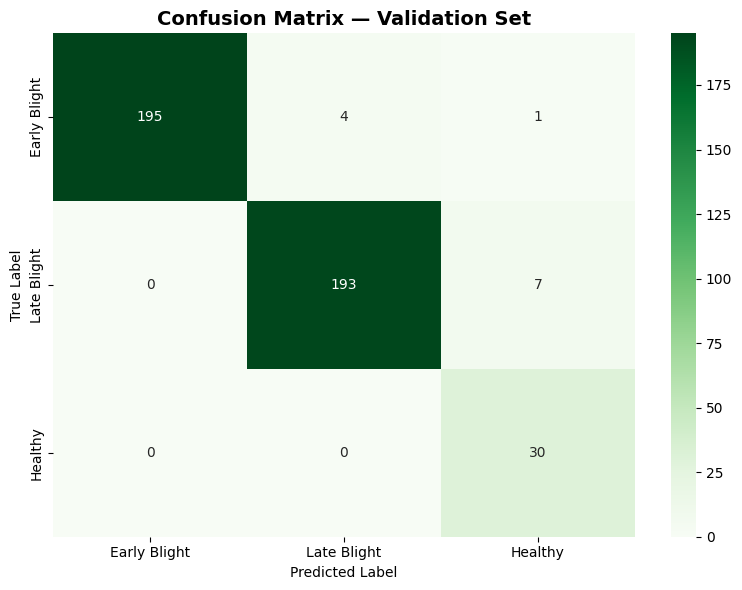


Detailed Classification Report:
              precision    recall  f1-score   support

Early Blight       1.00      0.97      0.99       200
 Late Blight       0.98      0.96      0.97       200
     Healthy       0.79      1.00      0.88        30

    accuracy                           0.97       430
   macro avg       0.92      0.98      0.95       430
weighted avg       0.98      0.97      0.97       430

✅ Confusion matrix saved!


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# Get correct class order from generator
class_names_ordered = list(validation_generator.class_indices.keys())
nice_names = [c.replace('Potato___', '').replace('_', ' ').title()
              for c in class_names_ordered]
print('Class order:', nice_names)

# Collect predictions and true labels together in one loop
validation_generator.reset()
y_true = []
y_pred = []

for i in range(len(validation_generator)):
    images, labels = validation_generator[i]
    preds = model.predict(images, verbose=0)
    y_true.extend(np.argmax(labels, axis=1))
    y_pred.extend(np.argmax(preds,  axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print(f'Total images evaluated: {len(y_true)}')
print(f'Overall Accuracy: {(y_true == y_pred).mean()*100:.2f}%')

# Plot confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=nice_names, yticklabels=nice_names)
plt.title('Confusion Matrix — Validation Set', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nDetailed Classification Report:')
print(classification_report(y_true, y_pred, target_names=nice_names))
print('✅ Confusion matrix saved!')


NameError: name 'class_dirs' is not defined

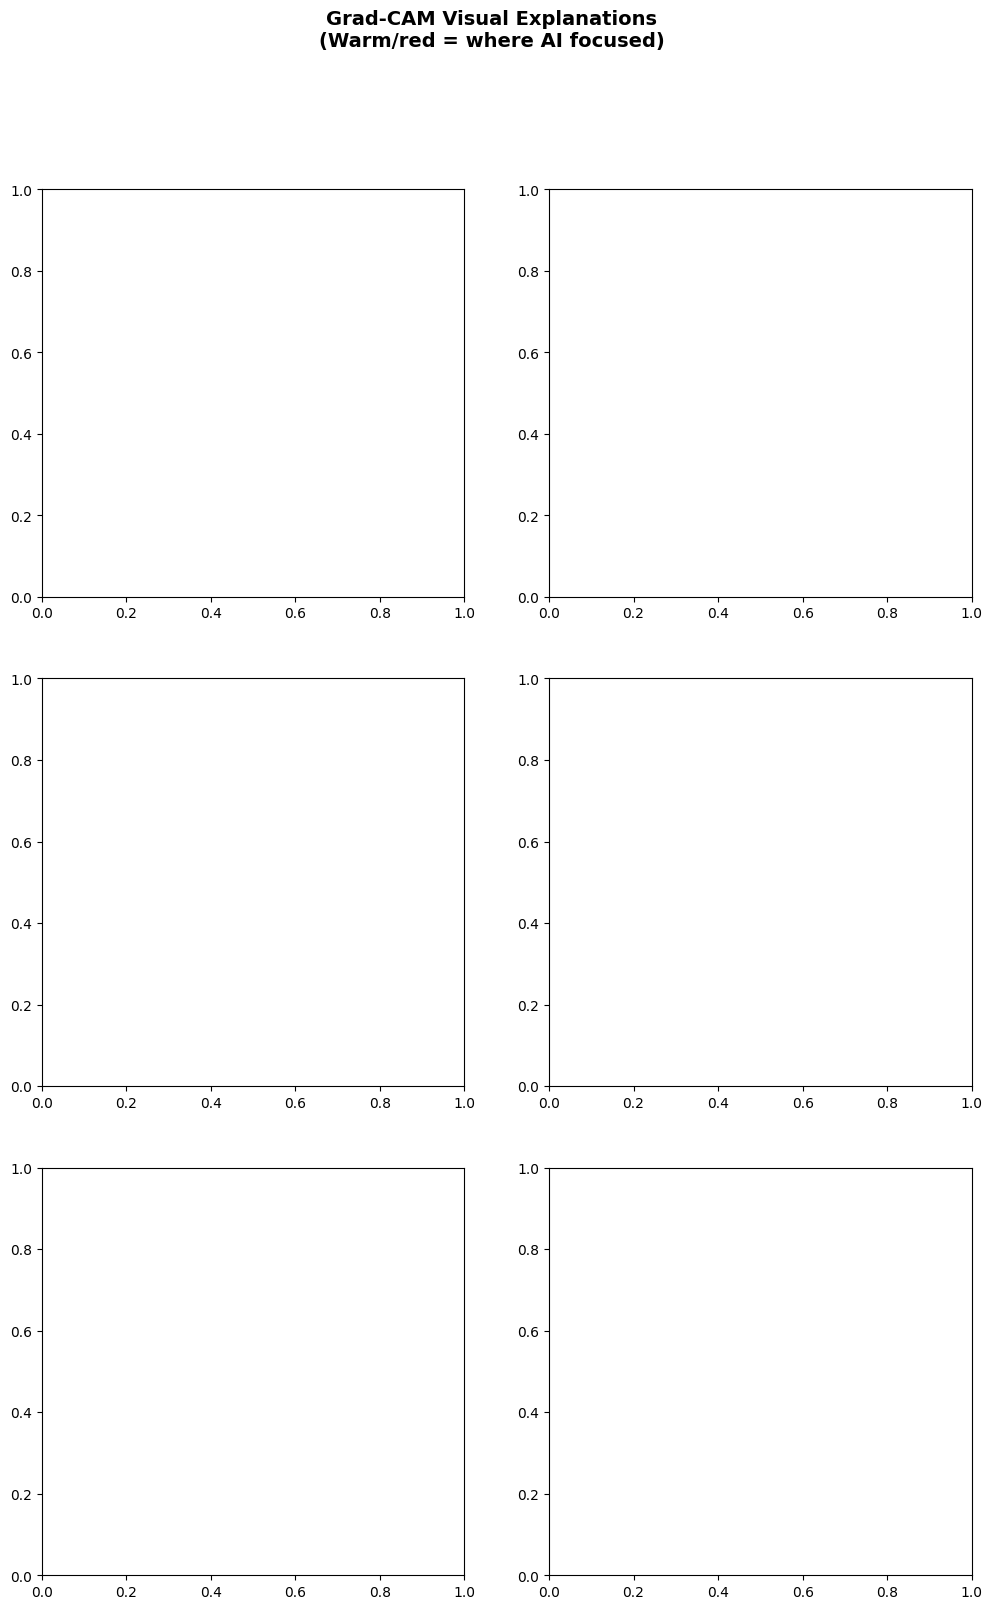

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import load_img, img_to_array

def make_gradcam_heatmap(img_array, model):
    # Use the known last conv layer name in EfficientNetB3
    last_conv_layer_name = 'top_conv'

    grad_model = tf.keras.models.Model(
        model.inputs,
        [model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), pred_index.numpy(), predictions.numpy()

def predict_and_explain(img_path):
    img = load_img(img_path, target_size=(300, 300))
    img_display = np.array(img)
    img_array = tf.keras.applications.efficientnet.preprocess_input(
        np.expand_dims(img_to_array(img), axis=0))

    heatmap, pred_idx, probs = make_gradcam_heatmap(img_array, model)

    heatmap_resized = cv2.resize(heatmap, (300, 300))
    heatmap_colored = cv2.applyColorMap(
        np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)
    overlay = (0.6 * img_display + 0.4 * heatmap_colored).astype(np.uint8)

    class_names = list(train_generator.class_indices.keys())
    pred_class  = class_names[pred_idx].replace('Potato___','').replace('_',' ')
    confidence  = probs[0][pred_idx] * 100

    return img_display, overlay, pred_class, confidence

# Test on one sample from each class
fig, axes = plt.subplots(3, 2, figsize=(12, 18))
fig.suptitle('Grad-CAM Visual Explanations\n(Warm/red = where AI focused)',
             fontsize=14, fontweight='bold')

for row, class_dir in enumerate(class_dirs):
    class_path = os.path.join(dataset_dir, class_dir)
    sample_img = os.path.join(class_path, os.listdir(class_path)[10])

    original, overlay, pred_class, confidence = predict_and_explain(sample_img)
    true_label = class_dir.replace('Potato___','').replace('_',' ')

    axes[row, 0].imshow(original)
    axes[row, 0].set_title(f'Original\nTrue: {true_label}', fontsize=11)
    axes[row, 0].axis('off')

    axes[row, 1].imshow(overlay)
    axes[row, 1].set_title(
        f'Grad-CAM Heatmap\nPredicted: {pred_class} ({confidence:.1f}%)',
        fontsize=11)
    axes[row, 1].axis('off')

plt.tight_layout()
plt.savefig('gradcam_explanations.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Grad-CAM visualisations saved!')

In [2]:
!pip install groq -q
from groq import Groq

# ⬇️ PASTE YOUR GROQ API KEY BETWEEN THE QUOTES BELOW
from groq import Groq
from google.colab import userdata
GROQ_API_KEY = userdata.get('GROQ_API_KEY')
groq_client = Groq(api_key=GROQ_API_KEY)

def get_llm_explanation(pred_class, confidence):
    prompt = f'''You are an expert agricultural assistant helping farmers.

The AI analysed a potato leaf and predicted:
- Diagnosis: {pred_class}
- Confidence: {confidence:.1f}%

Give a short practical response with:
1. What this disease means (1-2 sentences)
2. Visual signs to look for on the leaf (1-2 sentences)
3. What the farmer should do immediately (2-3 bullet points)
4. Whether the confidence level is reliable

Keep it simple, under 150 words.'''

    response = groq_client.chat.completions.create(
        model= 'openai/gpt-oss-120b',
        messages=[{'role': 'user', 'content': prompt}],
        max_tokens=250,
        temperature=0.7
    )
    return response.choices[0].message.content

# Test with Early Blight
print('Testing LLM explanation...\n')
print('─' * 50)
explanation = get_llm_explanation('Early Blight', 99.2)
print(explanation)
print('─' * 50)
print('\n✅ LLM explanation working!')


Testing LLM explanation...

──────────────────────────────────────────────────
**Early Blight (Alternaria solani)** – a fungal disease that attacks potato foliage, reducing photosynthesis and potentially lowering tuber yield.

**What you’ll see:**  
- Dark, concentric‑ringed lesions (target‑spot pattern) on older leaves, often with a yellow halo.  
- Leaves may turn yellow and die from the tip downwards.

**Immediate actions:**  
- Remove and destroy infected leaves and plant debris; do not compost.  
- Apply a fungicide labeled for early blight (e.g., chlorothalonil, mancozeb, or a systemic product such as azoxystrobin) according to label rates, repeating as needed.  
- Space plants properly (≥30 cm between rows) and avoid overhead irrigation to keep foliage dry.

**Confidence:** 99.2 % is very high; the diagnosis is reliable, but always confirm by checking several plants and consider a lab test if uncertain.
──────────────────────────────────────────────────

✅ LLM explanation workin

In [ ]:
!pip install gradio -q
import gradio as gr
import tempfile
from PIL import Image

def app_pipeline(image):
    # Save uploaded image temporarily
    with tempfile.NamedTemporaryFile(suffix='.jpg', delete=False) as tmp:
        image.save(tmp.name)
        tmp_path = tmp.name

    # Get prediction and heatmap
    original, overlay, pred_class, confidence = predict_and_explain(tmp_path)

    # Get LLM explanation
    explanation = get_llm_explanation(pred_class, confidence)

    # Format outputs
    diagnosis_text = f'🌿 DIAGNOSIS: {pred_class}\n📊 CONFIDENCE: {confidence:.1f}%'
    overlay_pil    = Image.fromarray(overlay)

    return diagnosis_text, overlay_pil, explanation

# Build the interface
interface = gr.Interface(
    fn=app_pipeline,
    inputs=gr.Image(
        type='pil',
        label='📷 Upload Potato Leaf Image'
    ),
    outputs=[
        gr.Textbox(label='🔍 Diagnosis Result',  lines=2),
        gr.Image (label='🗺️ AI Attention Heatmap'),
        gr.Textbox(label='💬 AI Explanation',     lines=8),
    ],
    title='🥔 Potato Plant Disease Detector — PRIDE',
    description='Upload a photo of a potato leaf. The AI will diagnose the disease, show where it looked on the leaf, and explain the diagnosis in plain English.',
    theme=gr.themes.Soft()
)

print('🚀 Launching web interface...')
print('Look for the public URL below — share it with anyone!\n')
interface.launch(share=True, debug=False)


🚀 Launching web interface...
Look for the public URL below — share it with anyone!

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://a55518e5eff1724956.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
from google.colab import files
import os

output_files = [
    'best_model.keras',
    'training_curves.png',
    'confusion_matrix.png',
    'gradcam_explanations.png',
    'class_distribution.png'
]

print('📦 Downloading output files...\n')
for f in output_files:
    if os.path.exists(f):
        files.download(f)
        print(f'  ✅ Downloaded: {f}')
    else:
        print(f'  ⚠️  Not found: {f}')

print('\n✅ All available files downloaded!')


📦 Downloading output files...



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

  ✅ Downloaded: best_model.keras


<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

  ✅ Downloaded: gradcam_explanations.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

  ✅ Downloaded: class_distribution.png

✅ All available files downloaded!
